# Few-Shot Learning — B15/N5 Results

**Split:** 15 base / 5 novel | **Protocol:** 5-way K-shot, 600 episodes, K∈{1,3,5}

**Backbones:** ResNet-50 · DeiT-S | **Methods:** NCC · ProtoNet · MatchingNet · MatchingNet+FCE · RelationNet · ProtoNet+TTA

**Novel (5):** AMERICAN BITTERN, AMERICAN COOT, AMERICAN FLAMINGO, AMERICAN GOLDFINCH, AMERICAN KESTREL

In [1]:

%matplotlib inline
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=120; plt.rcParams['savefig.dpi']=150
plt.rcParams['figure.facecolor']='white'; plt.rcParams['axes.facecolor']='white'

NB_DIR=os.getcwd()
ROOT=os.path.normpath(os.path.join(NB_DIR,'..'))
RES=os.path.join(ROOT,'results')
ANALYSIS=os.path.join(RES,'analysis')
os.makedirs(ANALYSIS,exist_ok=True)

PATHS={
    'full20_json'              :f'{RES}/birds20/baseline/resnet50/full20/summary.json',
    'base15_json'              :f'{RES}/birds20/baseline/resnet50/base15/base_test/summary.json',
    'kshot5_json'              :f'{RES}/birds20/baseline/resnet50/base15/novel_kshot_5/summary.json',
    'ncc_1shot_euc_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/1shot_euclidean/summary.json',
    'ncc_1shot_man_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/1shot_manhattan/summary.json',
    'ncc_3shot_euc_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/3shot_euclidean/summary.json',
    'ncc_3shot_man_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/3shot_manhattan/summary.json',
    'ncc_5shot_euc_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/5shot_euclidean/summary.json',
    'ncc_5shot_man_json'       :f'{RES}/birds20/baseline/resnet50/base15/novel_ncc/5shot_manhattan/summary.json',
    'proto_1shot_euc_json'     :f'{RES}/birds20/proto_net/base15_novel5/1shot_euclidean/summary.json',
    'proto_1shot_man_json'     :f'{RES}/birds20/proto_net/base15_novel5/1shot_manhattan/summary.json',
    'proto_3shot_euc_json'     :f'{RES}/birds20/proto_net/base15_novel5/3shot_euclidean/summary.json',
    'proto_3shot_man_json'     :f'{RES}/birds20/proto_net/base15_novel5/3shot_manhattan/summary.json',
    'proto_5shot_euc_json'     :f'{RES}/birds20/proto_net/base15_novel5/5shot_euclidean/summary.json',
    'proto_5shot_man_json'     :f'{RES}/birds20/proto_net/base15_novel5/5shot_manhattan/summary.json',
    'proto_5shot_euc_tta8_json':f'{RES}/birds20/proto_net/base15_novel5/5shot_euclidean_tta8/summary.json',
    'match_1shot_json'         :f'{RES}/birds20/matching_net/base15_novel5/1shot/summary.json',
    'match_3shot_json'         :f'{RES}/birds20/matching_net/base15_novel5/3shot/summary.json',
    'match_5shot_json'         :f'{RES}/birds20/matching_net/base15_novel5/5shot/summary.json',
    'match_fce_1shot_json'     :f'{RES}/birds20/matching_net_fce/base15_novel5/1shot/summary.json',
    'match_fce_3shot_json'     :f'{RES}/birds20/matching_net_fce/base15_novel5/3shot/summary.json',
    'match_fce_5shot_json'     :f'{RES}/birds20/matching_net_fce/base15_novel5/5shot/summary.json',
    'rel_1shot_json'           :f'{RES}/birds20/relation_net/base15_novel5/1shot/summary.json',
    'rel_3shot_json'           :f'{RES}/birds20/relation_net/base15_novel5/3shot/summary.json',
    'rel_5shot_json'           :f'{RES}/birds20/relation_net/base15_novel5/5shot/summary.json',
    'vit_ncc_1shot_euc_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/1shot_euclidean/summary.json',
    'vit_ncc_1shot_man_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/1shot_manhattan/summary.json',
    'vit_ncc_3shot_euc_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/3shot_euclidean/summary.json',
    'vit_ncc_3shot_man_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/3shot_manhattan/summary.json',
    'vit_ncc_5shot_euc_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/5shot_euclidean/summary.json',
    'vit_ncc_5shot_man_json'   :f'{RES}/birds20/vit/baseline/base15/novel_ncc/5shot_manhattan/summary.json',
    'vit_proto_1shot_euc_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/1shot_euclidean/summary.json',
    'vit_proto_1shot_man_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/1shot_manhattan/summary.json',
    'vit_proto_3shot_euc_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/3shot_euclidean/summary.json',
    'vit_proto_3shot_man_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/3shot_manhattan/summary.json',
    'vit_proto_5shot_euc_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/5shot_euclidean/summary.json',
    'vit_proto_5shot_man_json' :f'{RES}/birds20/vit/proto_net/base15_novel5/5shot_manhattan/summary.json',
}

R={}
for k,p in PATHS.items():
    if os.path.exists(p):
        with open(p) as f: R[k]=json.load(f)
    else:
        R[k]=None; print(f'  [missing] {k}')
present=sum(1 for v in R.values() if v is not None)
print(f'Loaded {present}/{len(R)} files.')

def acc(k): return float(R[k]['mean_accuracy_pct']) if R.get(k) else float('nan')
def ci(k):  return float(R[k]['ci95_pct'])          if R.get(k) else 0.0
def f1(k):  return float(R[k]['macro_f1'])          if R.get(k) and R[k].get('macro_f1') else float('nan')
SHOTS=[1,3,5]
NOVEL=['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO','AMERICAN GOLDFINCH','AMERICAN KESTREL']
SHORT=[c.replace('AMERICAN ','AM. ') for c in NOVEL]


Loaded 37/37 files.


---
## 1. Supervised Baselines (Reference)

In [2]:

for label,key,note in [('Full-20 Supervised','full20_json','Upper bound'),
                        ('Base-15 Supervised','base15_json','Base-class eval'),
                        ('K=5 Fine-tune (novel)','kshot5_json','Novel 5-shot finetune')]:
    d=R.get(key)
    if not d: print(f'{label}: [missing]'); continue
    a=float(d.get('accuracy',d.get('test_accuracy',0)))*100
    fm=d.get('macro_f1')
    fm_str=f'{float(fm):.4f}' if fm else '—'
    print(f'{label:<30} acc={a:.2f}%  F1={fm_str}  | {note}')


Full-20 Supervised             acc=99.00%  F1=0.9899  | Upper bound
Base-15 Supervised             acc=100.00%  F1=1.0000  | Base-class eval
K=5 Fine-tune (novel)          acc=100.00%  F1=—  | Novel 5-shot finetune


---
## 2. NCC: ResNet-50 vs DeiT-S

,Model,K-Shot,Accuracy(%),95% CI,F1
0,NCC/R50 (Euc),1,88.05,+-0.87,0.8773
1,NCC/R50 (Man),1,78.96,+-1.07,0.7926
2,NCC/DeiT-S (Euc),1,96.72,+-0.47,0.9671
3,NCC/DeiT-S (Man),1,96.53,+-0.49,0.9652
4,NCC/R50 (Euc),3,97.58,+-0.48,0.9755
5,NCC/R50 (Man),3,91.59,+-0.70,0.9159
6,NCC/DeiT-S (Euc),3,99.89,+-0.06,0.9989
7,NCC/DeiT-S (Man),3,99.86,+-0.06,0.9986
8,NCC/R50 (Euc),5,98.14,+-0.41,0.9813
9,NCC/R50 (Man),5,94.33,+-0.54,0.9425


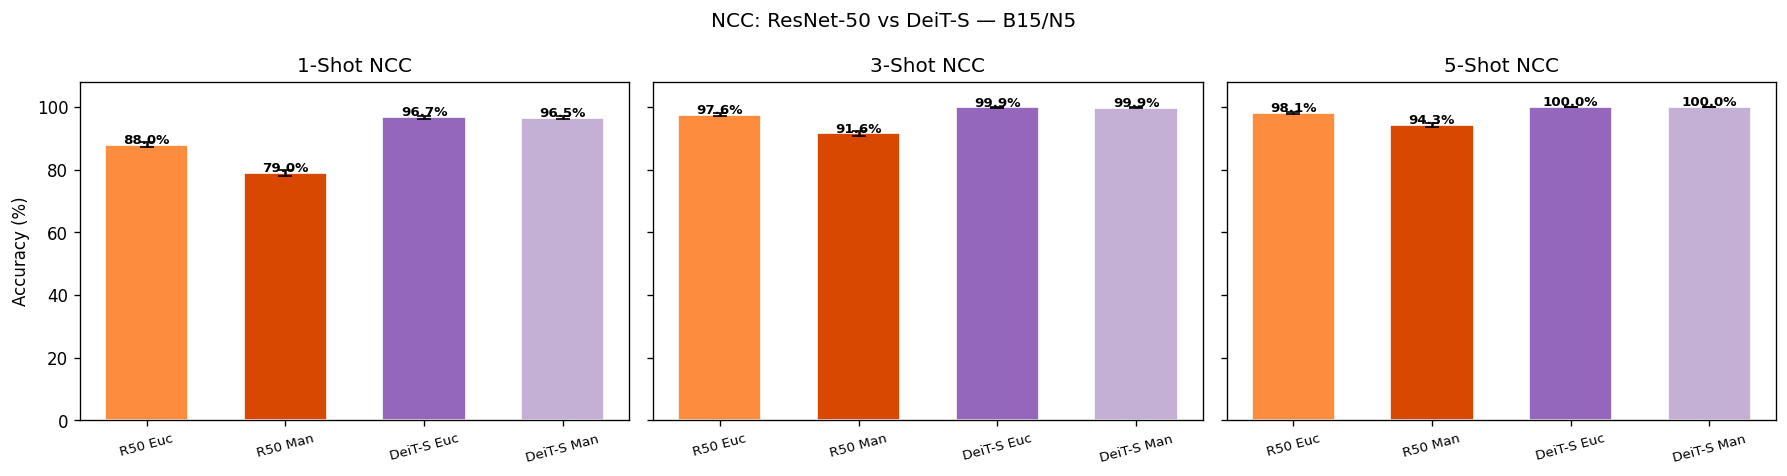

In [3]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('NCC/R50 (Euc)','ncc_{s}shot_euc_json'),('NCC/R50 (Man)','ncc_{s}shot_man_json'),
                        ('NCC/DeiT-S (Euc)','vit_ncc_{s}shot_euc_json'),('NCC/DeiT-S (Man)','vit_ncc_{s}shot_man_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))

fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,shot in zip(axes,SHOTS):
    cfgs=[('R50 Euc',f'ncc_{shot}shot_euc_json','#fd8d3c'),('R50 Man',f'ncc_{shot}shot_man_json','#d94801'),
           ('DeiT-S Euc',f'vit_ncc_{shot}shot_euc_json','#9467bd'),('DeiT-S Man',f'vit_ncc_{shot}shot_man_json','#c5b0d5')]
    ls=[c[0] for c in cfgs]; vs=[acc(c[1]) for c in cfgs]; es=[ci(c[1]) for c in cfgs]; cs=[c[2] for c in cfgs]
    bars=ax.bar(ls,vs,color=cs,edgecolor='white',width=0.6)
    ax.errorbar(range(len(ls)),vs,yerr=es,fmt='none',color='black',capsize=4)
    for bar,v in zip(bars,vs):
        ax.text(bar.get_x()+bar.get_width()/2,v+0.4,f'{v:.1f}%',ha='center',fontsize=8,fontweight='bold')
    ax.set_title(f'{shot}-Shot NCC'); ax.set_ylim(0,108)
    ax.set_ylabel('Accuracy (%)' if shot==1 else ''); ax.tick_params(axis='x',labelrotation=15,labelsize=8)
fig.suptitle('NCC: ResNet-50 vs DeiT-S — B15/N5',fontsize=12)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_ncc_r50_vs_deit.png',dpi=150); plt.show()


---
## 3. ProtoNet: ResNet-50 vs DeiT-S

,Model,K-Shot,Accuracy(%),95% CI,F1
0,ProtoNet/R50 (Euc),1,94.06,+-0.68,0.9397
1,ProtoNet/R50 (Man),1,79.67,+-1.01,0.7918
2,ProtoNet/DeiT-S (Euc),1,96.46,+-0.48,0.9640
3,ProtoNet/DeiT-S (Man),1,96.57,+-0.47,0.9652
4,ProtoNet/R50 (Euc),3,99.18,+-0.26,0.9918
5,ProtoNet/R50 (Man),3,89.63,+-0.77,0.8947
6,ProtoNet/DeiT-S (Euc),3,99.51,+-0.13,0.9951
7,ProtoNet/DeiT-S (Man),3,99.53,+-0.14,0.9953
8,ProtoNet/R50 (Euc),5,99.80,+-0.10,0.9980
9,ProtoNet/R50 (Man),5,93.29,+-0.61,0.9317


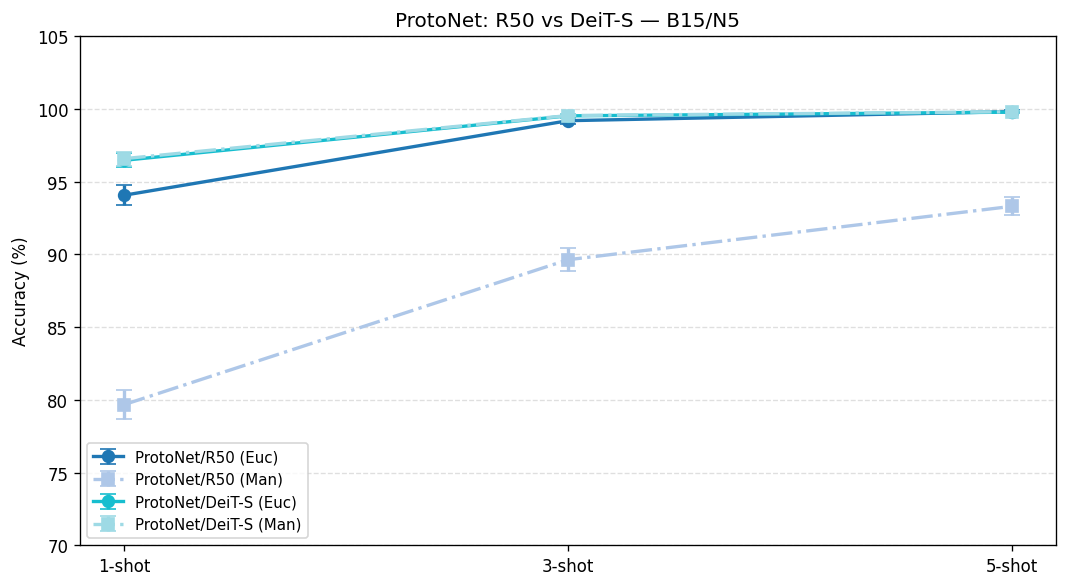

In [4]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('ProtoNet/R50 (Euc)','proto_{s}shot_euc_json'),('ProtoNet/R50 (Man)','proto_{s}shot_man_json'),
                        ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json'),('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))

fig,ax=plt.subplots(figsize=(9,5))
for label,tmpl,color,marker,ls in [('ProtoNet/R50 (Euc)','proto_{s}shot_euc_json','#1f77b4','o','-'),
                                     ('ProtoNet/R50 (Man)','proto_{s}shot_man_json','#aec7e8','s','-.'),
                                     ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json','#17becf','o','-'),
                                     ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json','#9edae5','s','-.')]:
    xs,ys,es=zip(*[(s,acc(tmpl.format(s=s)),ci(tmpl.format(s=s))) for s in SHOTS])
    ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,linestyle=ls,linewidth=2,markersize=7,capsize=5)
ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
ax.set_ylim(70,105); ax.set_ylabel('Accuracy (%)'); ax.legend(fontsize=9)
ax.set_title('ProtoNet: R50 vs DeiT-S — B15/N5'); ax.grid(axis='y',linestyle='--',alpha=0.4)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_protonet_r50_vs_deit.png',dpi=150); plt.show()


---
## 4. MatchingNet: Vanilla vs FCE (B15/N5)

FCE adds BiLSTM over support set + attention LSTM for query. Tests whether contextualised embeddings help.

,Model,K-Shot,Accuracy(%),95% CI,F1
0,MatchingNet (vanilla),1,60.93,+-0.88,0.5829
1,MatchingNet+FCE,1,63.79,+-0.71,0.5975
2,MatchingNet (vanilla),3,68.03,+-0.64,0.6455
3,MatchingNet+FCE,3,66.11,+-0.56,0.6175
4,MatchingNet (vanilla),5,70.87,+-0.59,0.6685
5,MatchingNet+FCE,5,67.24,+-0.46,0.6281


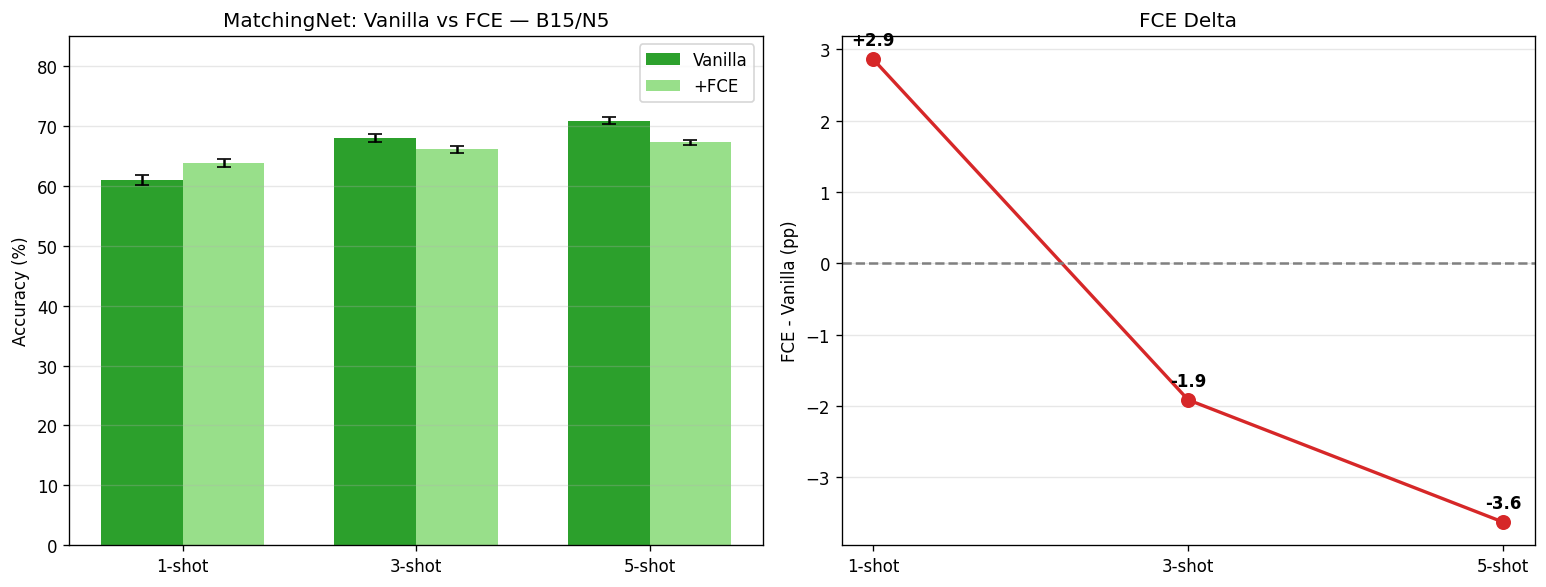

FCE effect: 1-shot: +2.86pp, 3-shot: -1.91pp, 5-shot: -3.63pp


In [5]:

rows=[]
for s in SHOTS:
    for label,tmpl in [('MatchingNet (vanilla)','match_{s}shot_json'),('MatchingNet+FCE','match_fce_{s}shot_json')]:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Model':label,'K-Shot':s,'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—','F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—'})
display(pd.DataFrame(rows))

fig,axes=plt.subplots(1,2,figsize=(13,5))
x=np.arange(len(SHOTS)); w=0.35
v_a=[acc(f'match_{s}shot_json') for s in SHOTS]; f_a=[acc(f'match_fce_{s}shot_json') for s in SHOTS]
v_c=[ci(f'match_{s}shot_json') for s in SHOTS];  f_c=[ci(f'match_fce_{s}shot_json') for s in SHOTS]
axes[0].bar(x-w/2,v_a,w,label='Vanilla',color='#2ca02c',yerr=v_c,capsize=4)
axes[0].bar(x+w/2,f_a,w,label='+FCE',   color='#98df8a',yerr=f_c,capsize=4)
axes[0].set_xticks(x); axes[0].set_xticklabels([f'{s}-shot' for s in SHOTS])
axes[0].set_ylim(0,85); axes[0].set_ylabel('Accuracy (%)'); axes[0].legend()
axes[0].set_title('MatchingNet: Vanilla vs FCE — B15/N5'); axes[0].grid(axis='y',alpha=0.3)
deltas=[acc(f'match_fce_{s}shot_json')-acc(f'match_{s}shot_json') for s in SHOTS]
axes[1].plot(SHOTS,deltas,'o-',color='#d62728',linewidth=2,markersize=8)
axes[1].axhline(0,color='gray',linestyle='--')
axes[1].set_xticks(SHOTS); axes[1].set_xticklabels([f'{s}-shot' for s in SHOTS])
axes[1].set_ylabel('FCE - Vanilla (pp)'); axes[1].set_title('FCE Delta')
for s,d in zip(SHOTS,deltas): axes[1].text(s,d+0.2,f'{d:+.1f}',ha='center',fontsize=10,fontweight='bold')
axes[1].grid(axis='y',alpha=0.3)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_matchingnet_fce.png',dpi=150); plt.show()
print('FCE effect: '+', '.join([f'{s}-shot: {d:+.2f}pp' for s,d in zip(SHOTS,deltas)]))


---
## 5. RelationNet (B15/N5)

In [6]:

print('RelationNet — B15/N5')
for s in SHOTS:
    k=f'rel_{s}shot_json'
    print(f'  {s}-shot: {acc(k):.2f}% +-{ci(k):.2f}  F1={f1(k):.4f}')


RelationNet — B15/N5
  1-shot: 72.71% +-0.94  F1=0.7233
  3-shot: 78.19% +-0.72  F1=0.7795
  5-shot: 78.75% +-0.64  F1=0.7842


---
## 6. ProtoNet + TTA (Test-Time Augmentation)

TTA averages 8 augmented views per query image at inference. No retraining.

ProtoNet/R50 5-shot Euclidean — TTA (B15/N5)
  Without TTA : 99.80% +-0.10
  With TTA x8 : 99.85% +-0.09
  Delta       : +0.05 pp


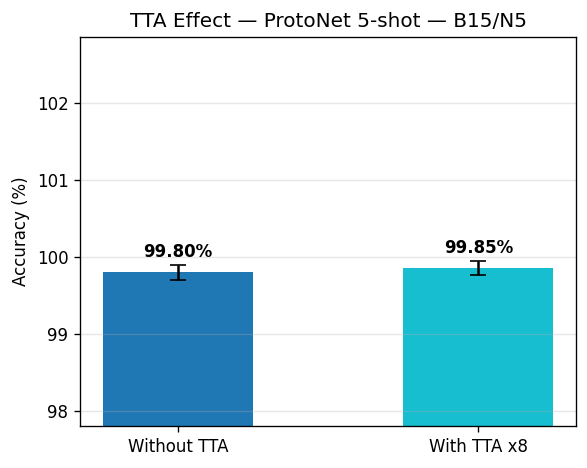

In [7]:

base_a=acc('proto_5shot_euc_json'); tta_a=acc('proto_5shot_euc_tta8_json')
base_c=ci('proto_5shot_euc_json');  tta_c=ci('proto_5shot_euc_tta8_json')
delta=tta_a-base_a
print(f'ProtoNet/R50 5-shot Euclidean — TTA (B15/N5)')
print(f'  Without TTA : {base_a:.2f}% +-{base_c:.2f}')
print(f'  With TTA x8 : {tta_a:.2f}% +-{tta_c:.2f}')
print(f'  Delta       : {delta:+.2f} pp')
fig,ax=plt.subplots(figsize=(5,4))
bars=ax.bar(['Without TTA','With TTA x8'],[base_a,tta_a],color=['#1f77b4','#17becf'],width=0.5)
ax.errorbar([0,1],[base_a,tta_a],yerr=[base_c,tta_c],fmt='none',color='black',capsize=5)
for bar,v in zip(bars,[base_a,tta_a]):
    ax.text(bar.get_x()+bar.get_width()/2,v+0.2,f'{v:.2f}%',ha='center',fontweight='bold')
ax.set_ylim(min(base_a,tta_a)-2,max(base_a,tta_a)+3); ax.set_ylabel('Accuracy (%)')
ax.set_title('TTA Effect — ProtoNet 5-shot — B15/N5'); ax.grid(axis='y',alpha=0.3)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_tta.png',dpi=150); plt.show()


---
## 7. K-Shot Trend — All Methods

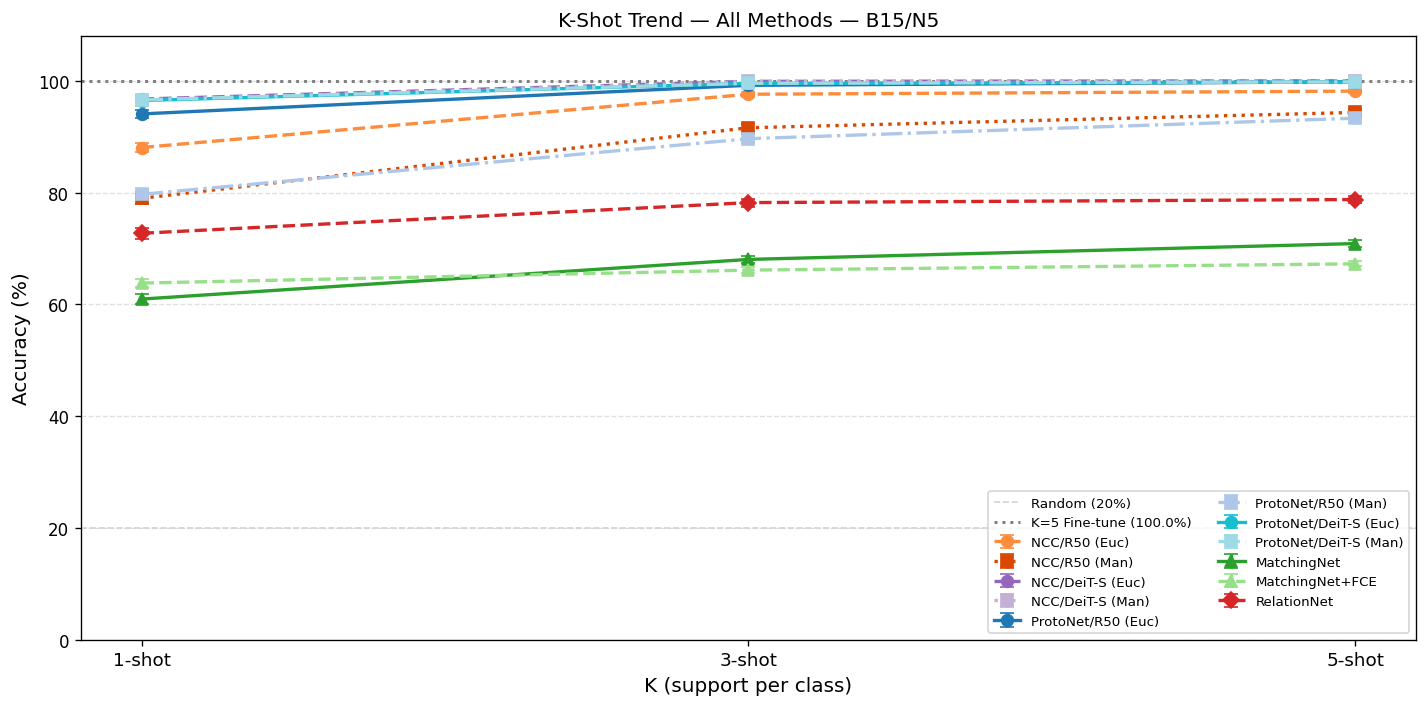

In [8]:

method_configs=[
    ('NCC/R50 (Euc)',         'ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',         'ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',      'vit_ncc_{s}shot_euc_json',     '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',      'vit_ncc_{s}shot_man_json',     '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',    'proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',    'proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json',   '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json',   '#9edae5','s','-.'),
    ('MatchingNet',           'match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',       'match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',           'rel_{s}shot_json',             '#d62728','D','--'),
]

fig,ax=plt.subplots(figsize=(12,6))
for label,tmpl,color,marker,ls in method_configs:
    xs,ys,es=[],[],[]
    for s in SHOTS:
        k=tmpl.format(s=s)
        if R.get(k): xs.append(s); ys.append(acc(k)); es.append(ci(k))
    if xs: ax.errorbar(xs,ys,yerr=es,label=label,color=color,marker=marker,linestyle=ls,linewidth=2,markersize=7,capsize=4)
ax.axhline(20,color='lightgray',linestyle='--',linewidth=1,label='Random (20%)')
ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS],fontsize=11)
ax.set_xlabel('K (support per class)',fontsize=12); ax.set_ylabel('Accuracy (%)',fontsize=12)
ax.set_ylim(0,108); ax.legend(loc='lower right',fontsize=8,ncol=2)
ax.grid(axis='y',linestyle='--',alpha=0.4)

ax.set_title('K-Shot Trend — All Methods — B15/N5')
kd=R.get('kshot5_json')
if kd:
    ref=float(kd.get('test_accuracy',kd.get('accuracy',0)))*100
    ax.axhline(ref,color='gray',linestyle=':',linewidth=1.8,label=f'K=5 Fine-tune ({ref:.1f}%)')
ax.legend(loc='lower right',fontsize=8,ncol=2)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_kshot_all.png',dpi=150); plt.show()


---
## 8. Per-Class Accuracy Heatmap

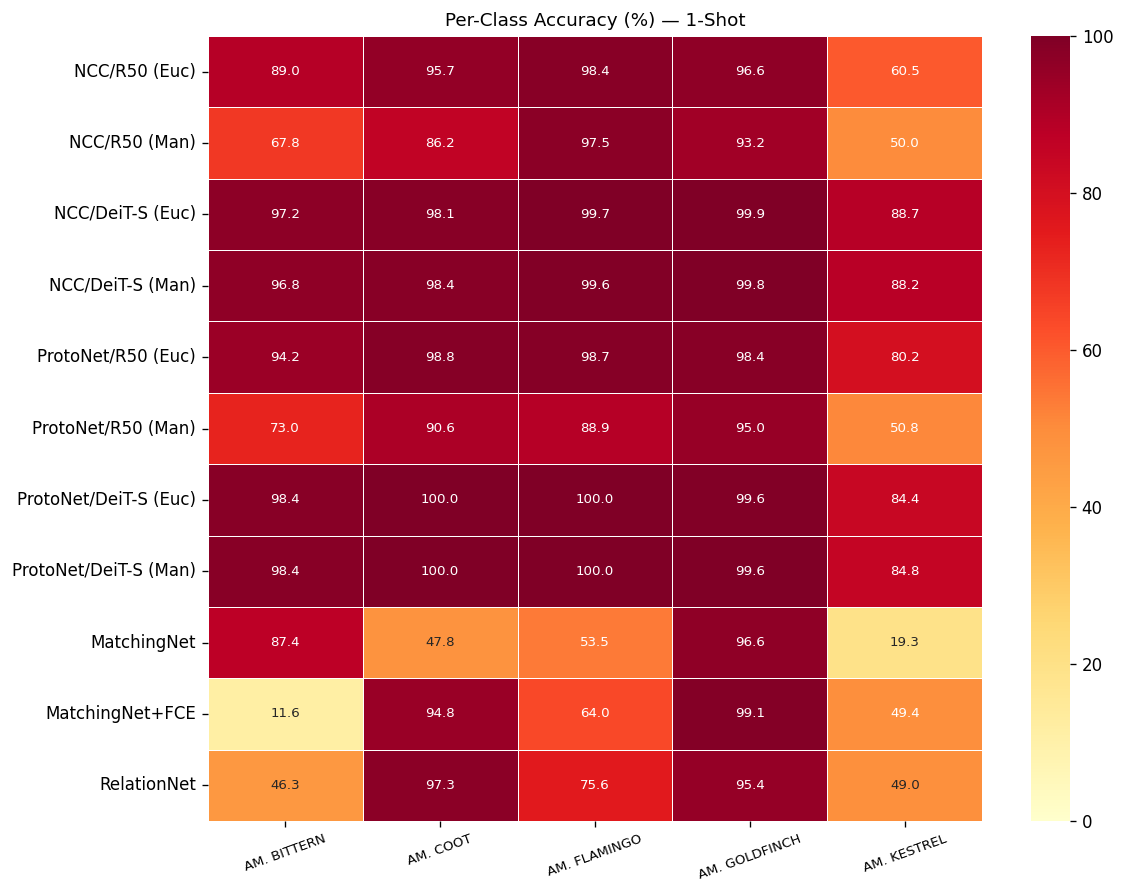

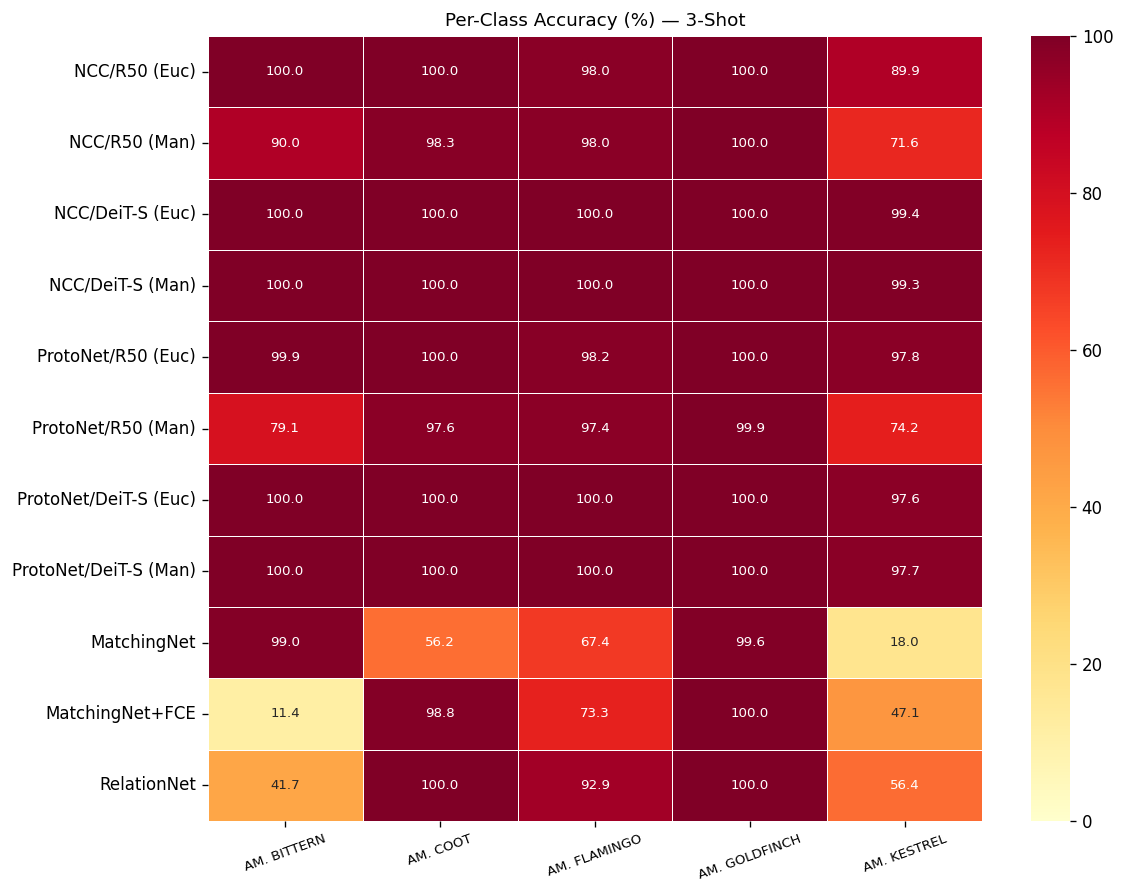

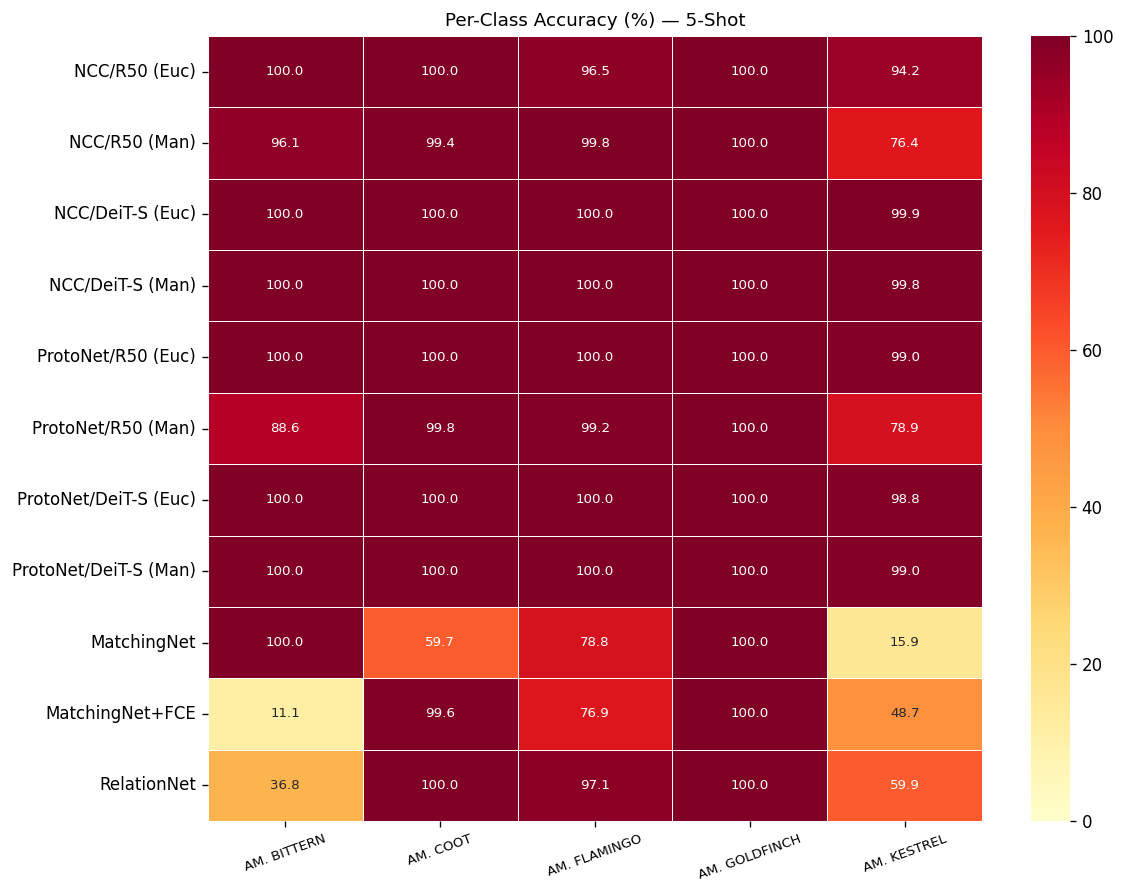

In [9]:

method_configs=[
    ('NCC/R50 (Euc)',         'ncc_{s}shot_euc_json',         '#fd8d3c','o','--'),
    ('NCC/R50 (Man)',         'ncc_{s}shot_man_json',         '#d94801','s',':'),
    ('NCC/DeiT-S (Euc)',      'vit_ncc_{s}shot_euc_json',     '#9467bd','o','--'),
    ('NCC/DeiT-S (Man)',      'vit_ncc_{s}shot_man_json',     '#c5b0d5','s',':'),
    ('ProtoNet/R50 (Euc)',    'proto_{s}shot_euc_json',       '#1f77b4','o','-'),
    ('ProtoNet/R50 (Man)',    'proto_{s}shot_man_json',       '#aec7e8','s','-.'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json',   '#17becf','o','-'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json',   '#9edae5','s','-.'),
    ('MatchingNet',           'match_{s}shot_json',           '#2ca02c','^','-'),
    ('MatchingNet+FCE',       'match_fce_{s}shot_json',       '#98df8a','^','--'),
    ('RelationNet',           'rel_{s}shot_json',             '#d62728','D','--'),
]

for shot in SHOTS:
    defs=[(label,R.get(tmpl.format(s=shot))) for label,tmpl,*_ in method_configs]
    matrix,row_labels,any_data=[],[],False
    for name,d in defs:
        if d and 'per_class_accuracy_pct' in d:
            pca=d['per_class_accuracy_pct']
            matrix.append([pca.get(c,float('nan')) for c in NOVEL]); any_data=True
        else: matrix.append([float('nan')]*len(NOVEL))
        row_labels.append(name)
    if not any_data: continue
    matrix=np.array(matrix,dtype=float)
    fig,ax=plt.subplots(figsize=(max(10,len(NOVEL)*1.2),len(method_configs)*0.55+1.5))
    sns.heatmap(matrix,annot=True,fmt='.1f',cmap='YlOrRd',
                xticklabels=SHORT,yticklabels=row_labels,
                ax=ax,vmin=0,vmax=100,linewidths=0.5,linecolor='white',
                annot_kws={'size':8},mask=np.isnan(matrix))
    ax.set_title(f'Per-Class Accuracy (%) — {shot}-Shot',fontsize=11)
    ax.tick_params(axis='x',labelrotation=20,labelsize=8); ax.tick_params(axis='y',labelrotation=0)
    plt.tight_layout(); plt.show()


---
## 9. Backbone Ablation: DeiT-S vs ResNet-50

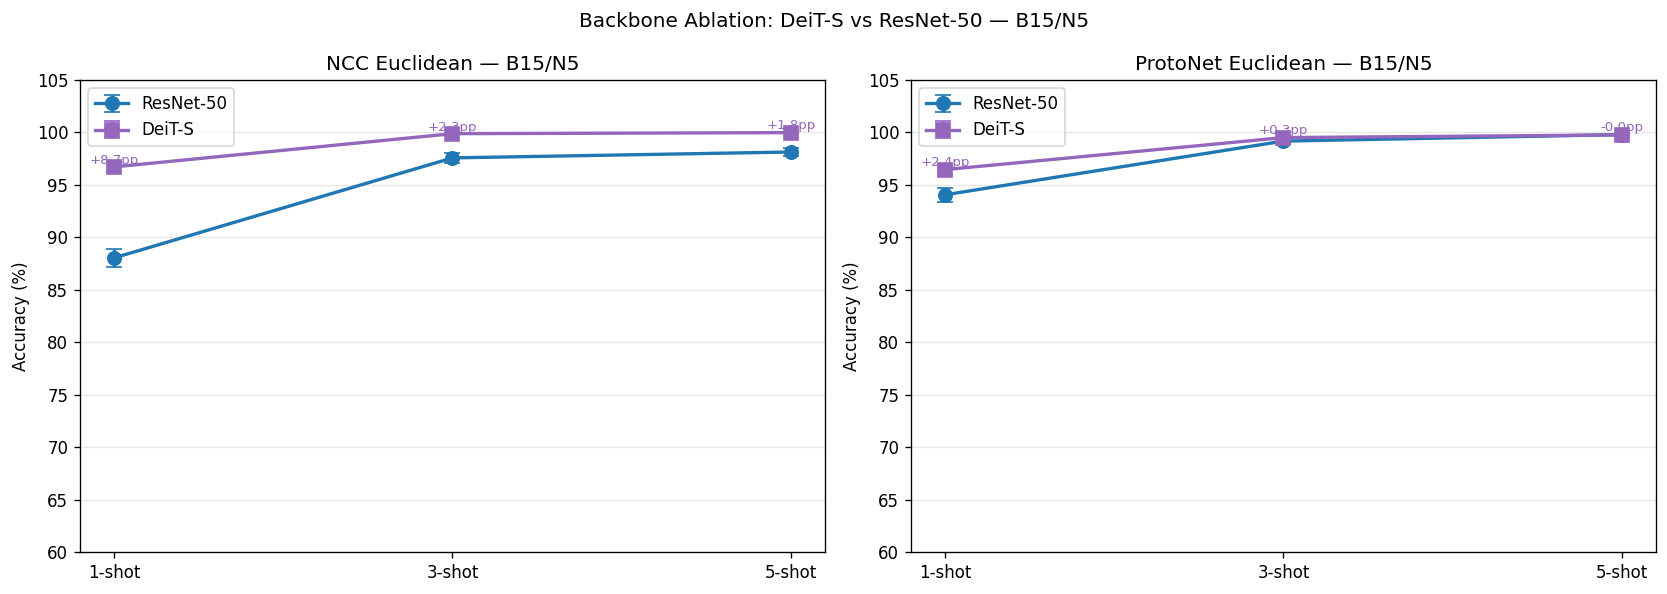

In [10]:

fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,(algo,r50t,vitr,title) in zip(axes,[
    ('NCC','ncc_{s}shot_euc_json','vit_ncc_{s}shot_euc_json','NCC Euclidean'),
    ('ProtoNet','proto_{s}shot_euc_json','vit_proto_{s}shot_euc_json','ProtoNet Euclidean'),
]):
    r50a=[acc(r50t.format(s=s)) for s in SHOTS]; vita=[acc(vitr.format(s=s)) for s in SHOTS]
    r50c=[ci(r50t.format(s=s)) for s in SHOTS];  vitc=[ci(vitr.format(s=s)) for s in SHOTS]
    ax.errorbar(SHOTS,r50a,yerr=r50c,label='ResNet-50',color='#1f77b4',marker='o',linewidth=2,markersize=8,capsize=5)
    ax.errorbar(SHOTS,vita,yerr=vitc,label='DeiT-S',   color='#9467bd',marker='s',linewidth=2,markersize=8,capsize=5)
    for s,r,v in zip(SHOTS,r50a,vita):
        if not np.isnan(r) and not np.isnan(v):
            ax.annotate(f'{v-r:+.1f}pp',(s,max(r,v)+0.3),ha='center',fontsize=8,color='#9467bd')
    ax.set_xticks(SHOTS); ax.set_xticklabels([f'{k}-shot' for k in SHOTS])
    ax.set_ylim(60,105); ax.set_ylabel('Accuracy (%)'); ax.set_title(f'{title} — B15/N5'); ax.legend()
    ax.grid(axis='y',alpha=0.3)
fig.suptitle('Backbone Ablation: DeiT-S vs ResNet-50 — B15/N5',fontsize=12)
plt.tight_layout(); plt.savefig(f'{ANALYSIS}/b15n5_backbone_ablation.png',dpi=150); plt.show()


---
## 10. Full Summary Table

In [11]:

rows=[]
methods=[
    ('NCC/R50 (Euc)','ncc_{s}shot_euc_json'),
    ('NCC/R50 (Man)','ncc_{s}shot_man_json'),
    ('NCC/DeiT-S (Euc)','vit_ncc_{s}shot_euc_json'),
    ('NCC/DeiT-S (Man)','vit_ncc_{s}shot_man_json'),
    ('ProtoNet/R50 (Euc)','proto_{s}shot_euc_json'),
    ('ProtoNet/R50 (Man)','proto_{s}shot_man_json'),
    ('ProtoNet/DeiT-S (Euc)','vit_proto_{s}shot_euc_json'),
    ('ProtoNet/DeiT-S (Man)','vit_proto_{s}shot_man_json'),
    ('MatchingNet','match_{s}shot_json'),
    ('MatchingNet+FCE','match_fce_{s}shot_json'),
    ('RelationNet','rel_{s}shot_json'),
]
for s in SHOTS:
    for label,tmpl in methods:
        k=tmpl.format(s=s); d=R.get(k)
        rows.append({'Method':label,'K-Shot':s,
                     'Accuracy(%)':f'{acc(k):.2f}' if d else '—',
                     '95% CI':f'+-{ci(k):.2f}' if d else '—',
                     'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—',
                     'Precision':f"{float(d['macro_precision']):.4f}" if d and d.get('macro_precision') else '—',
                     'Recall':f"{float(d['macro_recall']):.4f}" if d and d.get('macro_recall') else '—',
                     'AUC':f"{float(d['auc_ovr']):.4f}" if d and d.get('auc_ovr') else '—'})
k='proto_5shot_euc_tta8_json'; d=R.get(k)
rows.append({'Method':'ProtoNet/R50+TTA8 (Euc)','K-Shot':5,
             'Accuracy(%)':f'{acc(k):.2f}' if d else '—','95% CI':f'+-{ci(k):.2f}' if d else '—',
             'F1':f'{f1(k):.4f}' if d and not np.isnan(f1(k)) else '—',
             'Precision':f"{float(d['macro_precision']):.4f}" if d and d.get('macro_precision') else '—',
             'Recall':f"{float(d['macro_recall']):.4f}" if d and d.get('macro_recall') else '—',
             'AUC':f"{float(d['auc_ovr']):.4f}" if d and d.get('auc_ovr') else '—'})
df_s=pd.DataFrame(rows); df_s.index=range(1,len(df_s)+1)
display(df_s)
df_s.to_csv(f'{ANALYSIS}/b15n5_summary.csv')
print(f'Saved to {ANALYSIS}/b15n5_summary.csv')


,Method,K-Shot,Accuracy(%),95% CI,F1,Precision,Recall,AUC
1,NCC/R50 (Euc),1,88.05,+-0.87,0.8773,0.8960,0.8805,0.9857
2,NCC/R50 (Man),1,78.96,+-1.07,0.7926,0.8580,0.7896,0.9235
3,NCC/DeiT-S (Euc),1,96.72,+-0.47,0.9671,0.9691,0.9672,0.9996
4,NCC/DeiT-S (Man),1,96.53,+-0.49,0.9652,0.9674,0.9653,0.9974
5,ProtoNet/R50 (Euc),1,94.06,+-0.68,0.9397,0.9443,0.9406,0.9964
6,ProtoNet/R50 (Man),1,79.67,+-1.01,0.7918,0.8253,0.7967,0.9351
7,ProtoNet/DeiT-S (Euc),1,96.46,+-0.48,0.9640,0.9668,0.9646,0.9993
8,ProtoNet/DeiT-S (Man),1,96.57,+-0.47,0.9652,0.9678,0.9657,0.9972
9,MatchingNet,1,60.93,+-0.88,0.5829,0.5828,0.6093,0.8306
10,MatchingNet+FCE,1,63.79,+-0.71,0.5975,0.6268,0.6379,0.8871


Saved to Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results\analysis/b15n5_summary.csv


---
## 11. Key Insights

In [12]:

print('='*70)
print('  KEY FINDINGS — B15/N5')
print('='*70)

for algo,r50t,vitr in [('NCC','ncc_{s}shot_euc_json','vit_ncc_{s}shot_euc_json'),
                        ('ProtoNet','proto_{s}shot_euc_json','vit_proto_{s}shot_euc_json')]:
    print(f'\n{algo} — DeiT-S vs R50 lift (Euclidean):')
    for s in SHOTS:
        r=acc(r50t.format(s=s)); v=acc(vitr.format(s=s))
        print(f'  {s}-shot: DeiT-S={v:.2f}%  R50={r:.2f}%  delta={v-r:+.2f}pp')

print('\nMatchingNet FCE effect:')
for s in SHOTS:
    v=acc(f'match_{s}shot_json'); fce=acc(f'match_fce_{s}shot_json')
    print(f'  {s}-shot: FCE={fce:.2f}%  vanilla={v:.2f}%  delta={fce-v:+.2f}pp')

print(f'\nTTA (5-shot Euc): {acc("proto_5shot_euc_tta8_json"):.2f}% vs {acc("proto_5shot_euc_json"):.2f}%  delta={acc("proto_5shot_euc_tta8_json")-acc("proto_5shot_euc_json"):+.2f}pp')

print('\nRanking at 5-shot Euclidean:')
ranking=[('NCC/DeiT-S','vit_ncc_5shot_euc_json'),
         ('ProtoNet/DeiT-S','vit_proto_5shot_euc_json'),
         ('ProtoNet/R50+TTA8','proto_5shot_euc_tta8_json'),
         ('NCC/R50','ncc_5shot_euc_json'),
         ('ProtoNet/R50','proto_5shot_euc_json'),
         ('RelationNet','rel_5shot_json'),
         ('MatchingNet','match_5shot_json'),
         ('MatchingNet+FCE','match_fce_5shot_json')]
for i,(name,key) in enumerate(sorted(ranking,key=lambda x:acc(x[1]),reverse=True),1):
    print(f'  {i}. {name}: {acc(key):.2f}%')


  KEY FINDINGS — B15/N5

NCC — DeiT-S vs R50 lift (Euclidean):
  1-shot: DeiT-S=96.72%  R50=88.05%  delta=+8.67pp
  3-shot: DeiT-S=99.89%  R50=97.58%  delta=+2.31pp
  5-shot: DeiT-S=99.99%  R50=98.14%  delta=+1.85pp

ProtoNet — DeiT-S vs R50 lift (Euclidean):
  1-shot: DeiT-S=96.46%  R50=94.06%  delta=+2.40pp
  3-shot: DeiT-S=99.51%  R50=99.18%  delta=+0.33pp
  5-shot: DeiT-S=99.77%  R50=99.80%  delta=-0.03pp

MatchingNet FCE effect:
  1-shot: FCE=63.79%  vanilla=60.93%  delta=+2.86pp
  3-shot: FCE=66.11%  vanilla=68.03%  delta=-1.91pp
  5-shot: FCE=67.24%  vanilla=70.87%  delta=-3.63pp

TTA (5-shot Euc): 99.85% vs 99.80%  delta=+0.05pp

Ranking at 5-shot Euclidean:
  1. NCC/DeiT-S: 99.99%
  2. ProtoNet/R50+TTA8: 99.85%
  3. ProtoNet/R50: 99.80%
  4. ProtoNet/DeiT-S: 99.77%
  5. NCC/R50: 98.14%
  6. RelationNet: 78.75%
  7. MatchingNet: 70.87%
  8. MatchingNet+FCE: 67.24%
